# August 2026 baseline forecasting

This notebook forecasts statewide Minnesota food-shelf activity for **August 2026**:

- visits (the prepared `HouseholdsReg`-based measure),
- pounds distributed, and
- individuals served.

It begins with the prepared site-month file produced by the cleaning notebook. It does **not** redo data cleaning. Every historical fold uses information only through July 31 of its forecast year, and the final forecast uses information only through July 31, 2026.

## Modeling assumptions

- This is a small-sample regression/time-series task: only 55 statewide monthly observations are available.
- Interpretability and leakage prevention are more important than fitting a highly complex model.
- MAPE is the provisional primary metric; MAE, RMSE, median APE, and WAPE are supporting diagnostics.
- The official competition scoring rule is not yet incorporated.
- Reported outcomes are modeled. Prepared correction flags are retained, but flagged high values are not clipped or deleted.


## 1. Setup and load the prepared data

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
INPUT_PATH = ROOT / "Data" / "processed" / "foodshelf_site_month.csv"

FORECAST_YEAR = 2026
BACKTEST_YEARS = (2023, 2024, 2025)
METRICS = ("visits", "pounds", "individuals")
MODELS = (
    "seasonal_naive",
    "ytd_growth",
    "aug_jul_ratio",
    "trend_month_regression",
    "robust_ensemble",
)

assert INPUT_PATH.exists(), f"Prepared input not found: {INPUT_PATH}"
INPUT_PATH

WindowsPath('C:/Users/dinsa/OneDrive - UW-Madison/Documents/AA MINNEMUDAC/MINNEMUDAC_2026/Data/processed/foodshelf_site_month.csv')

In [2]:
usecols = [
    "month", "year", *METRICS,
    "flag_outlier", "flag_hh_gt_indiv", "flag_dup_summed", "flag_typo_fixed",
]
site_month = pd.read_csv(INPUT_PATH, usecols=usecols, parse_dates=["month"])
site_month["year"] = pd.to_numeric(site_month["year"], errors="raise").astype(int)

flag_summary = pd.Series({
    column: int(site_month[column].fillna(False).astype(bool).sum())
    for column in ["flag_outlier", "flag_hh_gt_indiv", "flag_dup_summed", "flag_typo_fixed"]
}, name="flagged_site_month_rows").to_frame()

monthly = (
    site_month.groupby("month", as_index=False)[list(METRICS)]
    .sum(min_count=1)
    .sort_values("month")
    .reset_index(drop=True)
)
monthly["year"] = monthly["month"].dt.year
monthly["month_num"] = monthly["month"].dt.month

profile = pd.DataFrame({
    "item": ["Site-month rows", "Statewide months", "First month", "Last month", "Missing statewide targets"],
    "value": [
        f"{len(site_month):,}",
        len(monthly),
        monthly["month"].min().strftime("%Y-%m"),
        monthly["month"].max().strftime("%Y-%m"),
        int(monthly[list(METRICS)].isna().sum().sum()),
    ],
})

display(profile)
display(flag_summary)

,item,value
0,Site-month rows,"28,101"
1,Statewide months,55
2,First month,2022-01
3,Last month,2026-07
4,Missing statewide targets,0


,flagged_site_month_rows
flag_outlier,43
flag_hh_gt_indiv,145
flag_dup_summed,28
flag_typo_fixed,7


### Data interpretation

The site-level records are aggregated to one statewide observation per month. The flags above are audit information—not reasons to remove observations. This matters because large values may represent real demand spikes rather than errors.


## 2. Cutoff and leakage checks

In [3]:
FINAL_CUTOFF = pd.Timestamp("2026-07-31")
FINAL_TARGET = pd.Timestamp("2026-08-01")

assert monthly["month"].max() <= FINAL_CUTOFF
assert monthly["month"].max() == pd.Timestamp("2026-07-01")
assert not monthly["month"].eq(FINAL_TARGET).any()
assert monthly[list(METRICS)].notna().all().all()

cutoff_checks = pd.DataFrame({
    "check": [
        "Latest source month",
        "August 2026 outcome present",
        "All statewide targets complete",
        "External predictors used",
    ],
    "result": [
        monthly["month"].max().strftime("%Y-%m"),
        bool(monthly["month"].eq(FINAL_TARGET).any()),
        bool(monthly[list(METRICS)].notna().all().all()),
        False,
    ],
    "required": ["2026-07", False, True, False],
})
cutoff_checks

,check,result,required
0,Latest source month,2026-07,2026-07
1,August 2026 outcome present,False,False
2,All statewide targets complete,True,True
3,External predictors used,False,False


## 3. Explore the statewide series

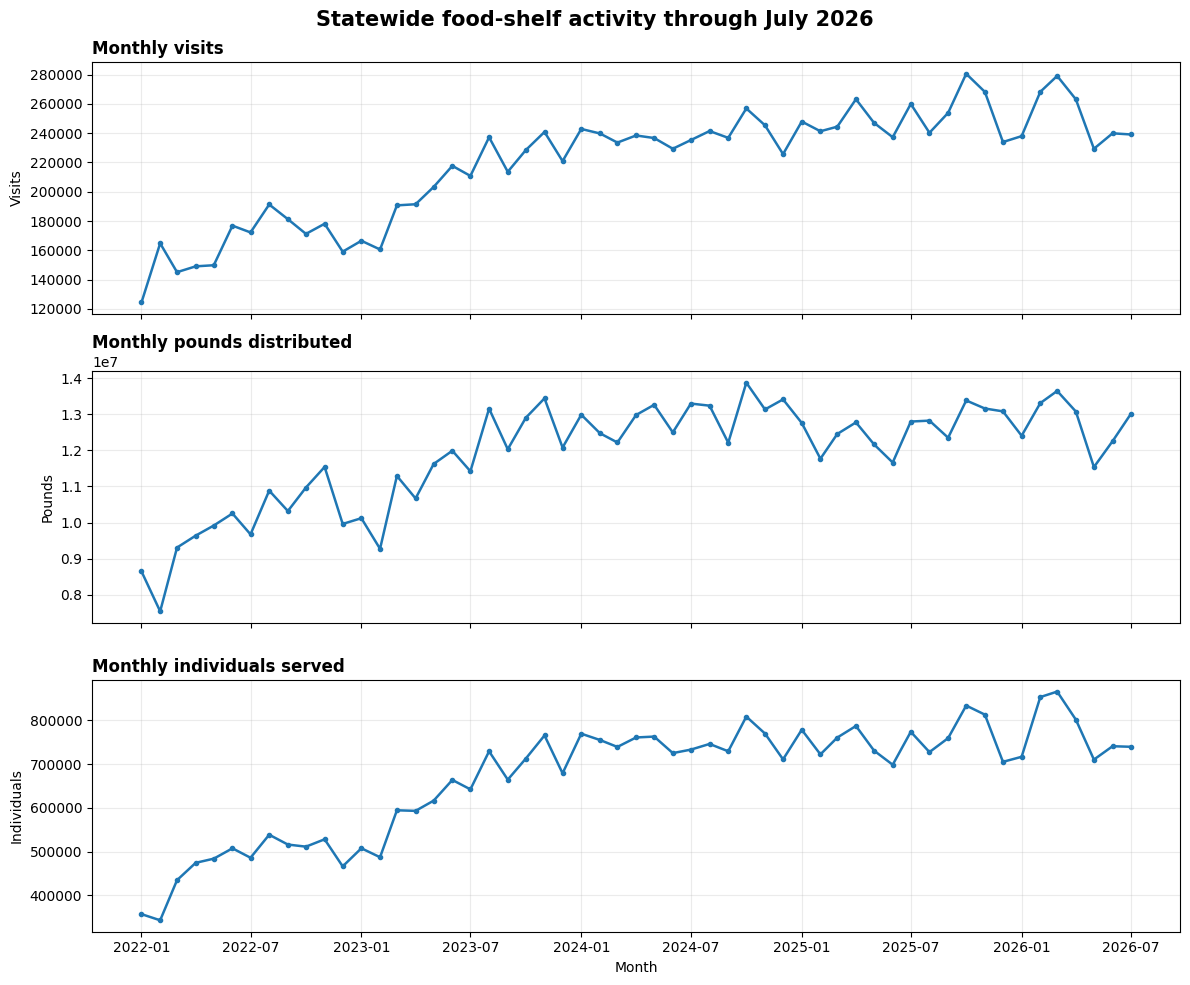

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
titles = {
    "visits": "Monthly visits",
    "pounds": "Monthly pounds distributed",
    "individuals": "Monthly individuals served",
}

for axis, metric in zip(axes, METRICS):
    axis.plot(monthly["month"], monthly[metric], marker="o", markersize=3, linewidth=1.8)
    axis.set_title(titles[metric], loc="left", fontweight="bold")
    axis.set_ylabel(metric.title())
    axis.grid(alpha=0.25)

axes[-1].set_xlabel("Month")
fig.suptitle("Statewide food-shelf activity through July 2026", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

In [5]:
recent_comparison = monthly.loc[
    monthly["month"].isin([pd.Timestamp("2025-08-01"), pd.Timestamp("2026-07-01")]),
    ["month", *METRICS],
].copy()
recent_comparison["month"] = recent_comparison["month"].dt.strftime("%Y-%m")
recent_comparison

,month,visits,pounds,individuals
43,2025-08,"240,290.000","12,821,574.420","727,272.000"
54,2026-07,"239,143.000","12,999,406.860","739,444.000"


## 4. Define the baseline models

The models deliberately use different simple signals:

1. **Seasonal naive:** repeat the previous August. This is the benchmark to beat.
2. **YTD growth:** scale the previous August by January–July year-over-year growth.
3. **August/July ratio:** apply the median historical August-to-July ratio to the current July.
4. **Trend + month regression:** estimate a linear trend and calendar-month effects using ordinary least squares.
5. **Robust ensemble:** take the median of the other four predictions, reducing dependence on one extreme estimate.

With only three historical August test cases, these transparent models are more defensible than a heavily tuned machine-learning model.


In [6]:
def trend_month_forecast(train, metric, target_date):
    ordered = train.sort_values("month").reset_index(drop=True)
    origin = ordered["month"].min()
    time_index = (
        (ordered["month"].dt.year - origin.year) * 12
        + ordered["month"].dt.month - origin.month
    ).to_numpy()
    target_index = (target_date.year - origin.year) * 12 + target_date.month - origin.month

    month_number = ordered["month"].dt.month.to_numpy()
    design = np.column_stack(
        [np.ones(len(ordered)), time_index]
        + [(month_number == month).astype(float) for month in range(2, 13)]
    )
    target_design = np.array(
        [1.0, float(target_index)]
        + [float(target_date.month == month) for month in range(2, 13)]
    )
    coefficients, *_ = np.linalg.lstsq(
        design, ordered[metric].to_numpy(dtype=float), rcond=None
    )
    return float(target_design @ coefficients)


def forecast_one_metric(train, metric, target_year):
    target_date = pd.Timestamp(target_year, 8, 1)

    prior_august = train.loc[
        (train["year"] == target_year - 1) & (train["month_num"] == 8), metric
    ]
    if len(prior_august) != 1:
        raise ValueError(f"Expected one prior August for {metric} in {target_year}")
    seasonal_naive = float(prior_august.iloc[0])

    current_ytd = train.loc[
        (train["year"] == target_year) & (train["month_num"] <= 7), metric
    ].sum()
    prior_ytd = train.loc[
        (train["year"] == target_year - 1) & (train["month_num"] <= 7), metric
    ].sum()
    ytd_growth = seasonal_naive * float(current_ytd / prior_ytd)

    historical_ratios = []
    for year in sorted(train["year"].unique()):
        july = train.loc[(train["year"] == year) & (train["month_num"] == 7), metric]
        august = train.loc[(train["year"] == year) & (train["month_num"] == 8), metric]
        if len(july) == 1 and len(august) == 1 and float(july.iloc[0]) != 0:
            historical_ratios.append(float(august.iloc[0] / july.iloc[0]))
    if not historical_ratios:
        raise ValueError(f"No historical August/July ratio for {metric} in {target_year}")

    current_july = float(train.loc[
        (train["year"] == target_year) & (train["month_num"] == 7), metric
    ].iloc[0])
    aug_jul_ratio = current_july * float(np.median(historical_ratios))
    trend = trend_month_forecast(train, metric, target_date)
    ensemble = float(np.median([seasonal_naive, ytd_growth, aug_jul_ratio, trend]))

    return {
        "seasonal_naive": seasonal_naive,
        "ytd_growth": ytd_growth,
        "aug_jul_ratio": aug_jul_ratio,
        "trend_month_regression": trend,
        "robust_ensemble": ensemble,
    }

## 5. Rolling August backtest

Each fold mimics the real forecasting decision. For example, the 2024 fold trains only through July 2024, generates every prediction, and only then retrieves the August 2024 actual for scoring.


In [7]:
def forecast_fold(monthly_data, target_year):
    cutoff = pd.Timestamp(target_year, 7, 31)
    train = monthly_data.loc[monthly_data["month"] <= cutoff].copy()
    assert train["month"].max() == pd.Timestamp(target_year, 7, 1)
    assert not ((train["year"] == target_year) & (train["month_num"] >= 8)).any()

    predictions = {
        metric: forecast_one_metric(train, metric, target_year)
        for metric in METRICS
    }

    actual_row = monthly_data.loc[monthly_data["month"] == pd.Timestamp(target_year, 8, 1)]
    if len(actual_row) != 1:
        raise ValueError(f"Missing held-out August actual for {target_year}")

    records = []
    for metric in METRICS:
        actual = float(actual_row.iloc[0][metric])
        for model, prediction in predictions[metric].items():
            error = prediction - actual
            records.append({
                "forecast_year": target_year,
                "cutoff": cutoff,
                "metric": metric,
                "model": model,
                "actual": actual,
                "prediction": prediction,
                "error": error,
                "absolute_error": abs(error),
                "absolute_percentage_error": abs(error) / actual,
            })
    return records


backtest_predictions = pd.DataFrame([
    row
    for year in BACKTEST_YEARS
    for row in forecast_fold(monthly, year)
])

display(backtest_predictions.head(10))
print(f"Created {len(backtest_predictions)} predictions across "
      f"{len(BACKTEST_YEARS)} folds, {len(METRICS)} outcomes, and {len(MODELS)} models.")

,forecast_year,cutoff,metric,model,actual,prediction,error,absolute_error,absolute_percentage_error
0,2023,2023-07-31,visits,seasonal_naive,"237,243.000","191,311.000","-45,932.000","45,932.000",0.194
1,2023,2023-07-31,visits,ytd_growth,"237,243.000","237,079.543",-163.457,163.457,0.001
2,2023,2023-07-31,visits,aug_jul_ratio,"237,243.000","234,193.465","-3,049.535","3,049.535",0.013
3,2023,2023-07-31,visits,trend_month_regression,"237,243.000","228,297.143","-8,945.857","8,945.857",0.038
4,2023,2023-07-31,visits,robust_ensemble,"237,243.000","231,245.304","-5,997.696","5,997.696",0.025
5,2023,2023-07-31,pounds,seasonal_naive,"13,154,185.780","10,885,355.600","-2,268,830.180","2,268,830.180",0.172
6,2023,2023-07-31,pounds,ytd_growth,"13,154,185.780","12,794,250.269","-359,935.511","359,935.511",0.027
7,2023,2023-07-31,pounds,aug_jul_ratio,"13,154,185.780","12,849,520.796","-304,664.984","304,664.984",0.023
8,2023,2023-07-31,pounds,trend_month_regression,"13,154,185.780","12,513,554.116","-640,631.664","640,631.664",0.049
9,2023,2023-07-31,pounds,robust_ensemble,"13,154,185.780","12,653,902.192","-500,283.588","500,283.588",0.038


Created 45 predictions across 3 folds, 3 outcomes, and 5 models.


In [8]:
def summarize_backtests(predictions):
    naive_ape = predictions.loc[
        predictions["model"].eq("seasonal_naive")
    ].set_index(["metric", "forecast_year"])["absolute_percentage_error"]

    rows = []
    for (metric, model), group in predictions.groupby(["metric", "model"], sort=False):
        ape = group["absolute_percentage_error"]
        rows.append({
            "metric": metric,
            "model": model,
            "folds": len(group),
            "mape": float(ape.mean()),
            "median_ape": float(ape.median()),
            "mae": float(group["absolute_error"].mean()),
            "rmse": float(np.sqrt(np.mean(np.square(group["error"])))),
            "wape": float(group["absolute_error"].sum() / group["actual"].sum()),
            "folds_better_than_naive": int(sum(
                row.absolute_percentage_error < naive_ape.loc[(metric, row.forecast_year)]
                for row in group.itertuples()
            )),
        })
    return pd.DataFrame(rows).sort_values(["metric", "mape", "model"]).reset_index(drop=True)


backtest_summary = summarize_backtests(backtest_predictions)

mape_table = (
    backtest_summary.pivot(index="model", columns="metric", values="mape")
    .loc[list(MODELS)]
    .mul(100)
)
mape_table.style.format("{:.2f}%").highlight_min(axis=0, color="#c6efce")

metric,individuals,pounds,visits
model,,,
seasonal_naive,10.32%,7.03%,7.20%
ytd_growth,9.79%,6.68%,9.02%
aug_jul_ratio,10.17%,9.65%,10.14%
trend_month_regression,15.49%,10.21%,13.06%
robust_ensemble,9.45%,8.11%,9.18%


In [9]:
diagnostic_table = backtest_summary.copy()
for column in ["mape", "median_ape", "wape"]:
    diagnostic_table[column] *= 100

diagnostic_table.style.format({
    "mape": "{:.2f}%",
    "median_ape": "{:.2f}%",
    "wape": "{:.2f}%",
    "mae": "{:,.0f}",
    "rmse": "{:,.0f}",
})

,metric,model,folds,mape,median_ape,mae,rmse,wape,folds_better_than_naive
0,individuals,robust_ensemble,3,9.45%,10.28%,"69,625","75,565",9.48%,1
1,individuals,ytd_growth,3,9.79%,2.68%,"72,783","108,146",9.91%,1
2,individuals,aug_jul_ratio,3,10.17%,10.23%,"74,643","87,673",10.17%,1
3,individuals,seasonal_naive,3,10.32%,2.56%,"75,367","111,020",10.27%,0
4,individuals,trend_month_regression,3,15.49%,17.31%,"113,798","124,665",15.50%,1
5,pounds,ytd_growth,3,6.68%,2.74%,"882,677","1,294,114",6.75%,2
6,pounds,seasonal_naive,3,7.03%,3.23%,"921,332","1,332,354",7.05%,0
7,pounds,robust_ensemble,3,8.11%,7.76%,"1,061,638","1,168,405",8.12%,1
8,pounds,aug_jul_ratio,3,9.65%,12.29%,"1,259,509","1,435,123",9.64%,1
9,pounds,trend_month_regression,3,10.21%,11.19%,"1,329,350","1,424,418",10.17%,1


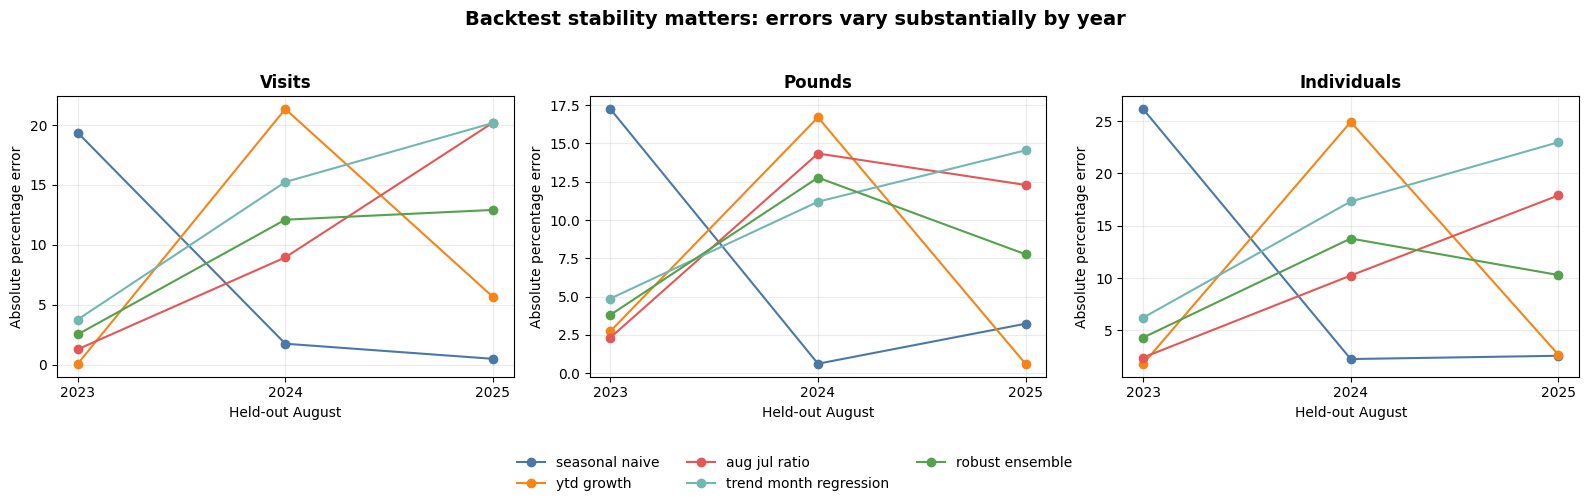

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)
colors = {
    "seasonal_naive": "#4c78a8",
    "ytd_growth": "#f58518",
    "aug_jul_ratio": "#e45756",
    "trend_month_regression": "#72b7b2",
    "robust_ensemble": "#54a24b",
}

for axis, metric in zip(axes, METRICS):
    metric_data = backtest_predictions.loc[backtest_predictions["metric"].eq(metric)]
    for model in MODELS:
        model_data = metric_data.loc[metric_data["model"].eq(model)]
        axis.plot(
            model_data["forecast_year"],
            model_data["absolute_percentage_error"] * 100,
            marker="o",
            label=model.replace("_", " "),
            color=colors[model],
        )
    axis.set_title(metric.title(), fontweight="bold")
    axis.set_xlabel("Held-out August")
    axis.set_ylabel("Absolute percentage error")
    axis.set_xticks(BACKTEST_YEARS)
    axis.grid(alpha=0.25)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
fig.suptitle("Backtest stability matters: errors vary substantially by year", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0.13, 1, 0.95))
plt.show()

## 6. Conservative model selection

A challenger replaces seasonal naive only if it has both:

1. lower mean MAPE, and
2. lower absolute percentage error in **all three** historical August folds.

This prevents selecting a model whose average looks better only because of one unusually strong year.


In [11]:
def select_models(summary):
    selected = {}
    for metric in METRICS:
        rows = summary.loc[summary["metric"].eq(metric)].copy()
        naive_mape = float(rows.loc[rows["model"].eq("seasonal_naive"), "mape"].iloc[0])
        eligible = rows.loc[
            ~rows["model"].eq("seasonal_naive")
            & rows["mape"].lt(naive_mape)
            & rows["folds_better_than_naive"].eq(len(BACKTEST_YEARS))
        ]
        selected[metric] = (
            str(eligible.sort_values("mape").iloc[0]["model"])
            if not eligible.empty
            else "seasonal_naive"
        )
    return selected


selected_models = select_models(backtest_summary)
selection_table = pd.DataFrame({
    "metric": METRICS,
    "selected_model": [selected_models[metric] for metric in METRICS],
    "reason": [
        "No challenger had lower mean MAPE and beat seasonal naive in all 3 folds"
        for _ in METRICS
    ],
})
selection_table

,metric,selected_model,reason
0,visits,seasonal_naive,No challenger had lower mean MAPE and beat sea...
1,pounds,seasonal_naive,No challenger had lower mean MAPE and beat sea...
2,individuals,seasonal_naive,No challenger had lower mean MAPE and beat sea...


## 7. Generate the August 2026 forecast

In [12]:
final_train = monthly.loc[monthly["month"] <= FINAL_CUTOFF].copy()
assert final_train["month"].max() == pd.Timestamp("2026-07-01")

final_records = []
for metric in METRICS:
    candidates = forecast_one_metric(final_train, metric, FORECAST_YEAR)
    for model, forecast in candidates.items():
        final_records.append({
            "forecast_month": "2026-08",
            "metric": metric,
            "model": model,
            "forecast": forecast,
            "selected": model == selected_models[metric],
        })

final_candidates = pd.DataFrame(final_records)
candidate_table = final_candidates.pivot(index="model", columns="metric", values="forecast").loc[list(MODELS)]
candidate_table.style.format("{:,.0f}").apply(
    lambda column: [
        "background-color: #c6efce" if final_candidates.loc[
            final_candidates["metric"].eq(column.name) & final_candidates["model"].eq(index),
            "selected",
        ].iloc[0] else ""
        for index in column.index
    ],
    axis=0,
)

metric,individuals,pounds,visits
model,,,
seasonal_naive,"727,272","12,821,574","240,290"
ytd_growth,"751,699","13,243,326","242,456"
aug_jul_ratio,"785,976","13,825,113","255,519"
trend_month_regression,"891,833","14,529,853","290,118"
robust_ensemble,"768,838","13,534,219","248,987"


In [13]:
recommended_forecast = final_candidates.loc[
    final_candidates["selected"], ["forecast_month", "metric", "model", "forecast"]
].copy()
recommended_forecast["reporting_value"] = recommended_forecast["forecast"].round().astype("int64")
recommended_forecast.style.format({"forecast": "{:,.2f}", "reporting_value": "{:,.0f}"})

,forecast_month,metric,model,forecast,reporting_value
0,2026-08,visits,seasonal_naive,"240,290.00","240,290"
5,2026-08,pounds,seasonal_naive,"12,821,574.42","12,821,574"
10,2026-08,individuals,seasonal_naive,"727,272.00","727,272"


## 8. Insights and interpretation

In [14]:
best_average = (
    backtest_summary.sort_values(["metric", "mape"])
    .groupby("metric", as_index=False)
    .first()[["metric", "model", "mape", "folds_better_than_naive"]]
)

print("KEY INSIGHTS")
print("------------")
for row in best_average.itertuples():
    print(
        f"- {row.metric.title()}: the lowest average-MAPE model was "
        f"{row.model.replace('_', ' ')} at {row.mape:.2%}; it beat seasonal naive "
        f"in {row.folds_better_than_naive} of {len(BACKTEST_YEARS)} folds."
    )

print()
print("- No challenger passed the all-three-fold consistency rule for any outcome.")
print("- Therefore, the recommended August 2026 values repeat August 2025.")
print("- The wide spread among candidate forecasts is model uncertainty, not a confidence interval.")
print("- Only three held-out August observations exist, so model rankings are fragile.")
print("- External SNAP, poverty, and MMG variables are intentionally excluded from this baseline.")
print("- Re-run model selection when the organizer confirms the official scoring metric.")

KEY INSIGHTS
------------
- Individuals: the lowest average-MAPE model was robust ensemble at 9.45%; it beat seasonal naive in 1 of 3 folds.
- Pounds: the lowest average-MAPE model was ytd growth at 6.68%; it beat seasonal naive in 2 of 3 folds.
- Visits: the lowest average-MAPE model was seasonal naive at 7.20%; it beat seasonal naive in 0 of 3 folds.

- No challenger passed the all-three-fold consistency rule for any outcome.
- Therefore, the recommended August 2026 values repeat August 2025.
- The wide spread among candidate forecasts is model uncertainty, not a confidence interval.
- Only three held-out August observations exist, so model rankings are fragile.
- External SNAP, poverty, and MMG variables are intentionally excluded from this baseline.
- Re-run model selection when the organizer confirms the official scoring metric.


### What the results mean

- **Visits:** seasonal naive has the best average August backtest accuracy. Although growth and ratio methods were much stronger in some individual years, they were not consistently better.
- **Pounds:** YTD growth has a slightly better average MAPE than seasonal naive, but loses in one of the three folds. The conservative rule therefore retains seasonal naive.
- **Individuals:** the robust ensemble has the lowest average MAPE, but it beats seasonal naive in only one fold. Its average advantage is not stable enough to justify switching.
- **Overall:** year-to-year August behavior is unstable, and three validation years are too few to support a complex or aggressively tuned model. Seasonal naive is the safest defensible hold forecast.

These forecasts should be treated as point estimates rather than uncertainty bounds. A future iteration should add prediction intervals and test statistical challengers only after the scoring rule and point-in-time availability of external features are confirmed.


## 9. Limitations and next steps

### Limitations

- The history begins in January 2022, leaving only three historical August holdouts.
- MAPE can behave poorly when actual values approach zero, although that is not an issue for these statewide totals.
- The final values do not include formal prediction intervals.
- Prepared data corrections occur upstream in the cleaning notebook; this notebook assumes that process is valid and reproducible.
- SNAP, ACS poverty, and Map the Meal Gap features are not used in this baseline.

### Recommended next steps

1. Confirm the official scoring rule and submission format.
2. Add prediction intervals using rolling residuals or a carefully specified bootstrap.
3. Compare ETS/SARIMA and regularized regression using the same cutoff-safe folds.
4. Introduce external features only after their historical publication dates are verified.
5. Keep seasonal naive as the benchmark; adopt a challenger only when improvement is stable rather than isolated to one year.
